Kaarina Mattika, CS82A, Section 1758
https://github.com/kmattika/cs82a-portfolio

# Washington state registration-to-voter gaps, 2020 to Present

**CS82A Final Project -- Prepared October 25, 2026**

**Research question:** Which racial/ethnic groups in Washington state have the largest and smallest registration-to-voter gaps over the last three general election cycles, and what can we project for 2026? Originally, I intended to look at data from 2018 to 2024, but the University of Washington Elections Database (UWED) does not have demographic data available prior to 2020, so I revised our research question accordingly. The findings in this research project conclude that Hispanic populations in Washington state have the highest proportion of registration-to-voter gaps, while White non-Hispanic voters have the largest registration-to-voter gaps in terms of total population. Our findings focus primarily on national elections results, as they are the most reliable indicator of an individual's voting presence (many voters only fill out the first page of a ballot, or sometimes, even just the first ballot line).

The insights derived from this project suggest that despite extensive legislation ensuring language parity in public communications materials, like voter outreach and health insurance mailers, as well as statewide vote-by-mail, these efforts are insufficient on their own in ensuring parity in electoral participation. Suggested solutions include partnering with affinity groups to hold ballot return efforts during the general election window, offering push-incentives to return ballots, and one-on-one inter-community engagement efforts.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from IPython.display import display
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.15)

### Section A -- Definition and Scope

First, we need to define the "Count Gap" and "Percentage Gap" that are the bedrock of our statistical modeling in this project. Here, **R** stands for estimated active registrations and **V** stands for estimated accepted ballots for the same affinity group and calendar year. Additionally, in lieu of using 'racial/ethnic' as group classifications, I have decided to use the updated anthropological term 'affinity group' instead, given that demographic data is self-reported in this dataset (as well as most other datasets of this nature in The United States). The rationale is that, because of it's self-reported nature, a respondent is actively choosing to identify with an affinity group of their own definition that is matched to their understanding of reportable demographics. 

- **Count gap:** `R - V`.
- **Percentage gap:** `100 * (R - V) / R`.

The percentage is the primary comparison because the five affinity groups of interest have vastly different sizes, with the 'count gap' describes the scale of the gap. For example, a 25% gap means that the accepted-ballot estimate is 25% below the registration estimate for that group.

UWED estimates racial/ethnic counts with Bayesian Improved Surname Geocoding (BISG), which has a strong track record of predicting an individual respondent's affinity group status using a pair of datasets (reported surnames and Census geocoding) and Bayesian estimation. Counts can be fractional because they sum modeled probabilities. White non-Hispanic, Black non-Hispanic, Asian non-Hispani, Other non-Hispanic, and Hispanic (of any race) are the five affinity groups provided by UWED's dataset. Of note: 'Other' combines American Indian/Alaska Native, Native Hawaiian/Pacific Islander,
and multiracial categories. These files do not provide data to separate age, gender, income, or education comparisons due to the limited nature of BISG used to create the initial dataset.

### Section B -- Initial Data Preparation

In [2]:
registrants = pd.read_csv(r'C:\Users\kamat\OneDrive\Desktop\CS82A Final Project\registrants_ld.csv')
voters = pd.read_csv(r'C:\Users\kamat\OneDrive\Desktop\CS82A Final Project\voters_ld.csv')

print('Registrants', registrants.shape)
display(registrants.head(10))
print('Voters', voters.shape)
display(voters.head(10))

Registrants (150, 9)


,State,District,Year,Total_Pop,White_Pop,Black_Pop,Hispanic_Pop,Asian_Pop,OtherRace_Pop
0,Washington,1.0,2020,103375,74354.690801,2551.669422,5132.329651,12396.361400,8939.948727
1,Washington,2.0,2020,101207,75069.684503,4412.453810,6883.075964,3514.410060,11327.375664
2,Washington,3.0,2020,103405,85590.550384,2627.607259,3971.685966,1885.424414,9329.731977
3,Washington,4.0,2020,108663,94417.756962,1434.843750,3646.189855,1395.851838,7768.357596
4,Washington,5.0,2020,107774,82812.147814,1838.136510,4893.743135,9392.528435,8837.444106
5,Washington,6.0,2020,101983,84928.438443,2062.190591,3880.772931,2233.263829,8878.334206
6,Washington,7.0,2020,104629,84484.996950,399.139443,8053.057012,456.830209,11234.976386
7,Washington,8.0,2020,93860,69818.637930,1355.037113,14751.529857,2115.702116,5819.092985
8,Washington,9.0,2020,98007,83936.342576,1081.302260,4823.226706,1705.605709,6460.522749
9,Washington,10.0,2020,112135,93154.396145,1824.402277,5799.168126,2046.989037,9310.044415


Voters (150, 11)


,State,District,Year,Election,Election_date,Total_Pop,White_Pop,Black_Pop,Hispanic_Pop,Asian_Pop,OtherRace_Pop
0,Washington,1.0,2020,General_Nov__3_2020,2020-11-03,90733,65858.337855,2218.493939,4309.467102,10530.442171,7816.258934
1,Washington,2.0,2020,General_Nov__3_2020,2020-11-03,79118,59392.610756,3475.658893,4852.146756,2547.177772,8850.405823
2,Washington,3.0,2020,General_Nov__3_2020,2020-11-03,84390,70443.674330,2013.726808,3039.547757,1443.260989,7449.790116
3,Washington,4.0,2020,General_Nov__3_2020,2020-11-03,87681,76590.808438,1133.291038,2721.143607,1055.398917,6180.358000
4,Washington,5.0,2020,General_Nov__3_2020,2020-11-03,92794,71536.774677,1604.022483,4028.241953,7979.633426,7645.327461
5,Washington,6.0,2020,General_Nov__3_2020,2020-11-03,81903,68950.402896,1530.950980,2804.934961,1665.013031,6951.698132
6,Washington,7.0,2020,General_Nov__3_2020,2020-11-03,87986,72549.875586,338.029562,6000.539999,389.779154,8707.775698
7,Washington,8.0,2020,General_Nov__3_2020,2020-11-03,71514,54829.380875,1021.367531,9606.289169,1557.207268,4499.755158
8,Washington,9.0,2020,General_Nov__3_2020,2020-11-03,82309,70722.103466,921.400354,3854.861910,1405.740899,5404.893372
9,Washington,10.0,2020,General_Nov__3_2020,2020-11-03,95070,79865.988230,1403.095472,4393.799987,1615.948659,7791.167652


In [3]:
print('Registration info page')
registrants.info()

print('Voters info page')
voters.info()

Registration info page
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   State          150 non-null    str    
 1   District       147 non-null    float64
 2   Year           150 non-null    int64  
 3   Total_Pop      150 non-null    int64  
 4   White_Pop      150 non-null    float64
 5   Black_Pop      150 non-null    float64
 6   Hispanic_Pop   150 non-null    float64
 7   Asian_Pop      150 non-null    float64
 8   OtherRace_Pop  150 non-null    float64
dtypes: float64(6), int64(2), str(1)
memory usage: 12.1 KB
Voters info page
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   State          150 non-null    str    
 1   District       147 non-null    float64
 2   Year           150 non-null    int64  
 3   Elect

**Data Cleaning Notes**

We must note that there are three null values in each of these datasets, which all appear in the 'District' column. While the data counts here are still inside the state of Washington, we are not able to assign District information on them. Our results should not be affected by these null counts, as we are not currently using District as a controlling variable. Thus, these rows are retained without modification.

### Section C -- Filtering and Preparing Data

Our data is separated annually in the registration file, and the voter file contains multiple elections per year. I have selected the exact General Election dates to control for only the highest-turnout election on those years, and to omit miscounting from introducing special elections and primary elections as part of the same count, which would inflate voter participation numbers.

In [4]:
years = [2020, 2022, 2024]

selected_registrants = registrants.loc[
    (registrants['Year'] == 2020) |
    (registrants['Year'] == 2022) |
    (registrants['Year'] == 2024)
].copy()

voters['Election_date'] = pd.to_datetime(voters['Election_date'], errors='raise')
selected_voters = voters.loc[
    (voters['Election_date'] == '2020-11-03') |
    (voters['Election_date'] == '2022-11-08') |
    (voters['Election_date'] == '2024-11-05')
].copy()

observed_years = sorted(selected_voters['Year'].unique())
coverage_rows = []
for year in years:
    registration_rows = selected_registrants.loc[selected_registrants['Year'] == year]
    ballot_rows = selected_voters.loc[selected_voters['Year'] == year]
    coverage_rows.append({
        'Year': year,
        'Cycle': 'Presidential' if year in [2020, 2024] else 'Midterm',
        'Registration rows': len(registration_rows),
        'Voter rows': len(ballot_rows),
        'Gap available': 'Yes' if len(ballot_rows) > 0 else 'No: voter data unavailable'
    })

coverage = pd.DataFrame(coverage_rows)
display(coverage)

,Year,Cycle,Registration rows,Voter rows,Gap available
0,2020,Presidential,50,50,Yes
1,2022,Midterm,50,50,Yes
2,2024,Presidential,50,50,Yes


Here, I also wanted to ensure that there was no duplicated data that would skew the data for our affinity groups in either direction. I used an 'if--raise' code scheme to flag the presence of any duplicate data points, which not only flags potential issues in this current dataset, but also allows the code to be replicable with other datasets of similar schema. With the hope of using this program to analyze future data sets, and possibly automate the analysis of upcoming elections at scale, having a robust data cleaning and validation scheme is critical to producing useful data.

I have also printed out the rows retained in both datasets in support of my argument to retain them - tens of thousands of individual datapoints would be removed from our dataset without good reason if we removed them.

In [5]:
data_checks = []
if selected_registrants.duplicated(['Year', 'District']).any():
    raise ValueError('Duplicate registration year/district keys.')
if selected_voters.duplicated(['Year', 'District']).any():
    raise ValueError('Duplicate voter year/district keys in the selected elections.')
data_checks.append({'Check': 'Selected source keys', 'Result': 'PASS',
                    'Detail': 'One row per year/district, including one unassigned row.'})

for year in years:
    rows = selected_registrants.loc[selected_registrants['Year'] == year]
    if len(rows) != 50 or rows['District'].nunique() != 49 or rows['District'].isna().sum() != 1:
        raise ValueError(f'Unexpected registration geography coverage in {year}.')
for year in observed_years:
    rows = selected_voters.loc[selected_voters['Year'] == year]
    if len(rows) != 50 or rows['District'].nunique() != 49 or rows['District'].isna().sum() != 1:
        raise ValueError(f'Unexpected voter geography coverage in {year}.')
data_checks.append({'Check': 'Geographic coverage', 'Result': 'PASS',
                    'Detail': '49 assigned districts plus one retained unassigned row in each available year.'})

print('Unassigned registration rows retained:')
display(selected_registrants.loc[selected_registrants['District'].isna(), ['Year', 'Total_Pop']])
print('Unassigned accepted-ballot rows retained:')
display(selected_voters.loc[selected_voters['District'].isna(), ['Year', 'Total_Pop']])

Unassigned registration rows retained:


,Year,Total_Pop
49,2020,17
99,2022,11
149,2024,1330


Unassigned accepted-ballot rows retained:


,Year,Total_Pop
49,2020,64695
99,2022,21710
149,2024,87421


### Section D -- Calculating Registration-Voter Gaps 

I have grouped data by year to retain all source rows, including unassigned geography. I then sum registrations and accepted ballots first, then divide. An unweighted mean of district percentages would provide data that is not germane to the original question under investigation in this project. I have built further error checks with if--raise schemes in the case of any gap proportions resolving to be equal to zero or a negative number, which would more readily alert a novice user that their data is being read incorrectly by the program. 

In [6]:
group_names = {
    'Hispanic_Pop': 'Hispanic',
    'Asian_Pop': 'Asian',
    'Black_Pop': 'Black',
    'OtherRace_Pop': 'Other',
    'White_Pop': 'White'
}

affinity_groups = list(group_names.keys())
population_columns = ['Total_Pop'] + affinity_groups

registration_totals = selected_registrants.groupby('Year')[population_columns].sum()
voter_totals = selected_voters.groupby('Year')[population_columns].sum()

registration_totals = registration_totals.loc[[2020, 2022, 2024]]
voter_totals = voter_totals.loc[[2020, 2022, 2024]]

for name, totals in {'Registrants': registration_totals, 'Voters': voter_totals}.items():
    difference = totals[affinity_groups].sum(axis=1) - totals['Total_Pop']

if (registration_totals[affinity_groups] <= 0).any().any():
    raise ValueError('A registration denominator is zero or negative.')

count_gap_table = registration_totals[affinity_groups] - voter_totals[affinity_groups]
percentage_gap_table = 100 * count_gap_table / registration_totals[affinity_groups]
percentage_gap_table = percentage_gap_table.rename(columns=group_names)
count_gap_table = count_gap_table.rename(columns=group_names)

print('Percentage gaps:')
display(percentage_gap_table.round(2))

Percentage gaps:


,Hispanic,Asian,Black,Other,White
Year,,,,,
2020,25.15,18.75,16.59,16.56,14.31
2022,56.48,48.07,43.60,36.52,31.92
2024,35.46,29.33,24.37,22.20,18.38


In [7]:
years = [2020, 2022, 2024]
result_rows = []
for year in years:
    for column, group in group_names.items():
        registrations = registration_totals.loc[year, column]
        if year in observed_years:
            ballots = voter_totals.loc[year, column]
            status = 'Observed estimate'
        else:
            ballots = np.nan
            status = 'Voter data unavailable'
        result_rows.append({
            'year': year,
            'group': group,
            'registrants': registrations,
            'voters': ballots,
            'gap_count': registrations - ballots,
            'gap_pct': 100 * (registrations - ballots) / registrations,
            'status': status
        })

results = pd.DataFrame(result_rows)
results = results.sort_values('year', ascending=True)
results = results.reset_index(drop=True)
observed_results = results.dropna(subset=['gap_pct']).copy()
if ((observed_results['gap_pct'] < 0) | (observed_results['gap_pct'] > 100)).any():
    raise ValueError('A statewide gap is outside 0–100%; investigate rather than clipping it.')
data_checks.append({'Check': 'Statewide denominators and gaps', 'Result': 'PASS',
                    'Detail': 'Positive denominators; all observed gaps lie between 0% and 100%.'})

display(results.round(2))

,year,group,registrants,voters,gap_count,gap_pct,status
0,2020,Hispanic,379944.11,284377.71,95566.40,25.15,Observed estimate
1,2020,Asian,358365.46,291181.65,67183.81,18.75,Observed estimate
2,2020,Black,189231.88,157839.79,31392.10,16.59,Observed estimate
3,2020,Other,419708.85,350184.26,69524.59,16.56,Observed estimate
4,2020,White,3525991.69,3021450.60,504541.09,14.31,Observed estimate
5,2022,Hispanic,395564.19,172130.18,223434.01,56.48,Observed estimate
6,2022,Asian,373491.87,193940.42,179551.45,48.07,Observed estimate
7,2022,Black,182990.05,103197.33,79792.71,43.60,Observed estimate
8,2022,Other,410035.55,260308.91,149726.64,36.52,Observed estimate
9,2022,White,3433096.35,2337322.15,1095774.20,31.92,Observed estimate


My original question wanted to discover the largest and smallest registration-to-voter gaps, which the following selection will do for us. As our gap percentages are already calculated, we just have to sort them in their own dataframe. We can see here that the largest percentage gaps for all three cycles between 2020 and 2024 are Hispanics, with the smallest gaps belonging to non-Hispanic Whites. In terms of absolute numbers, the largest gap by raw count are non-Hispanic Whites, and the smallest count (reflective of the smaller population) are non-Hispanic Blacks. This helps demonstrate the value of viewing these gaps as a proportion of a whole, rather than looking at raw population counts of our affinity groups - a one in ten raw count is a louder, but more skewed and less honest reported result than a nine in one-hundred proportional count.

In [8]:
winner_rows = []
for year in observed_years:
    annual = observed_results.loc[observed_results['year'] == year]
    by_rate = annual.sort_values('gap_pct', ascending=False)
    by_count = annual.sort_values('gap_count', ascending=False)
    winner_rows.append({
        'Year': year,
        'Largest percentage gap': by_rate.iloc[0]['group'],
        'Largest gap (%)': by_rate.iloc[0]['gap_pct'],
        'Smallest percentage gap': by_rate.iloc[-1]['group'],
        'Smallest gap (%)': by_rate.iloc[-1]['gap_pct'],
        'Largest count gap': by_count.iloc[0]['group'],
        'Smallest count gap': by_count.iloc[-1]['group']
    })
winners = pd.DataFrame(winner_rows)
display(winners.round(2))

,Year,Largest percentage gap,Largest gap (%),Smallest percentage gap,Smallest gap (%),Largest count gap,Smallest count gap
0,2020,Hispanic,25.15,White,14.31,White,Black
1,2022,Hispanic,56.48,White,31.92,White,Black
2,2024,Hispanic,35.46,White,18.38,White,Black


### Section E -- Visualizing Results

Bar charts are selected when comparing individual results against one another, as a pie chart makes it more difficult to discern proportional differences with more than three categories. A line chart is also used to emphasize the participation gaps between Presidential Election years (2020 and 2024) and Midterm Election years (2022). In 2020, the results clearly show a clear, disporportionate gap in election participation parity impacting Hispanics at abnormally higher rates compared to other affinity groups. However, the 2022 midterm election data shows each affinity group having a relatively unique registration-to-voter gap - the average difference between each affinity group is a 6.15 percent, compared to 2.73 in 2020 and 4.28 in 2024. Not only does this validate the common assumption that Midterm Elections are more volatile when it comes to voter turnout, but it also gives us a stronger baseline assumption for participation in non-Miderm years.

,group,registrants,voters,gap_count,gap_pct
0,Hispanic,379944.11,284377.71,95566.40,25.15
1,Asian,358365.46,291181.65,67183.81,18.75
2,Black,189231.88,157839.79,31392.10,16.59
3,Other,419708.85,350184.26,69524.59,16.56
4,White,3525991.69,3021450.60,504541.09,14.31


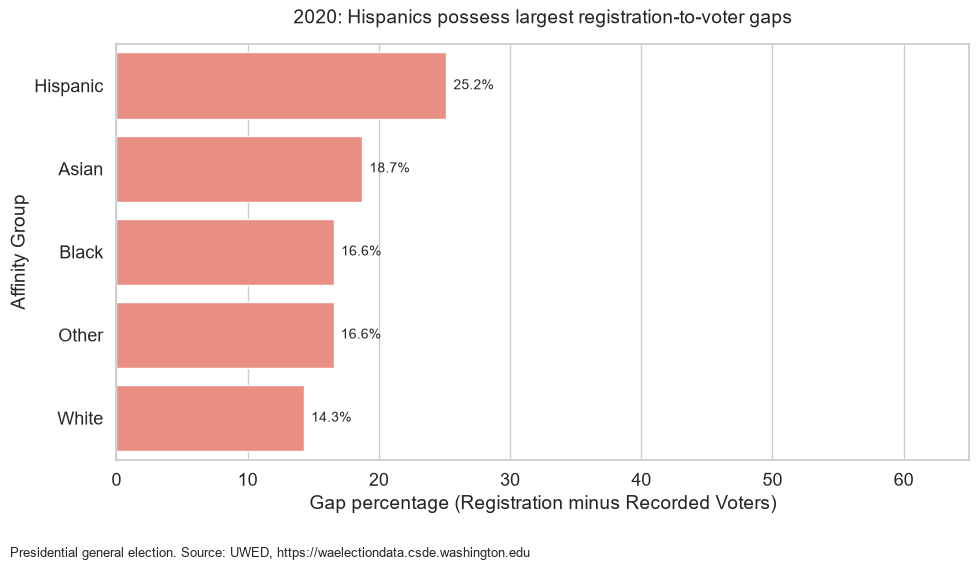

In [9]:
annual = observed_results.loc[observed_results['year'] == 2020].copy()
display(annual[['group', 'registrants', 'voters', 'gap_count', 'gap_pct']].round(2))

by_rate = annual.sort_values('gap_pct', ascending=False)
fig, ax = plt.subplots(figsize=(10, 5.8))
sns.barplot(data=by_rate, x='gap_pct', y='group', order=by_rate['group'],
            color='salmon', errorbar=None, ax=ax)
ax.set_xlim(0, 65)
ax.set_title('2020: Hispanics possess largest registration-to-voter gaps', pad=15)
ax.set_xlabel('Gap percentage (Registration minus Recorded Voters)')
ax.set_ylabel('Affinity Group')
for position in range(len(by_rate)):
    value = by_rate.iloc[position]['gap_pct']
    ax.annotate(f'{value:.1f}%', xy=(value, position), xytext=(5, 0),
                textcoords='offset points', va='center', fontsize=10)
fig.text(0.02, 0.02, 'Presidential general election. Source: UWED, https://waelectiondata.csde.washington.edu', fontsize=9)
fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

,group,registrants,voters,gap_count,gap_pct
5,Hispanic,395564.19,172130.18,223434.01,56.48
6,Asian,373491.87,193940.42,179551.45,48.07
7,Black,182990.05,103197.33,79792.71,43.60
8,Other,410035.55,260308.91,149726.64,36.52
9,White,3433096.35,2337322.15,1095774.20,31.92


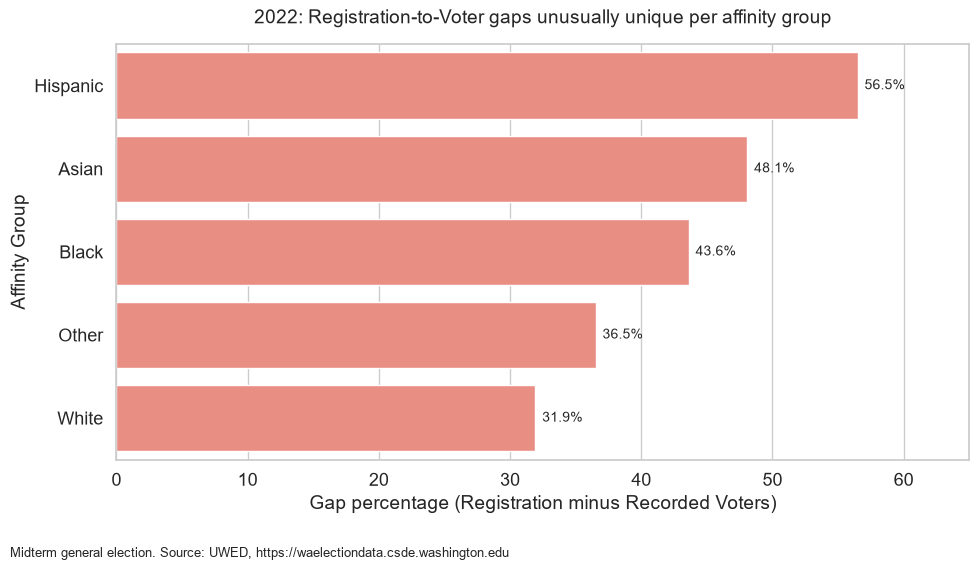

In [10]:
annual = observed_results.loc[observed_results['year'] == 2022].copy()
display(annual[['group', 'registrants', 'voters', 'gap_count', 'gap_pct']].round(2))

by_rate = annual.sort_values('gap_pct', ascending=False)
fig, ax = plt.subplots(figsize=(10, 5.8))
sns.barplot(data=by_rate, x='gap_pct', y='group', order=by_rate['group'],
            color='salmon', errorbar=None, ax=ax)
ax.set_xlim(0, 65)
ax.set_title('2022: Registration-to-Voter gaps unusually unique per affinity group', pad=15)
ax.set_xlabel('Gap percentage (Registration minus Recorded Voters)')
ax.set_ylabel('Affinity Group')
for position in range(len(by_rate)):
    value = by_rate.iloc[position]['gap_pct']
    ax.annotate(f'{value:.1f}%', xy=(value, position), xytext=(5, 0),
                textcoords='offset points', va='center', fontsize=10)
fig.text(0.02, 0.02, 'Midterm general election. Source: UWED, https://waelectiondata.csde.washington.edu', fontsize=9)
fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

,group,registrants,voters,gap_count,gap_pct
10,Hispanic,443519.96,286261.24,157258.73,35.46
11,Asian,414253.75,292765.78,121487.98,29.33
12,Black,190940.74,144402.62,46538.12,24.37
13,Other,428227.78,333174.73,95053.05,22.20
14,White,3555639.76,2901971.63,653668.13,18.38


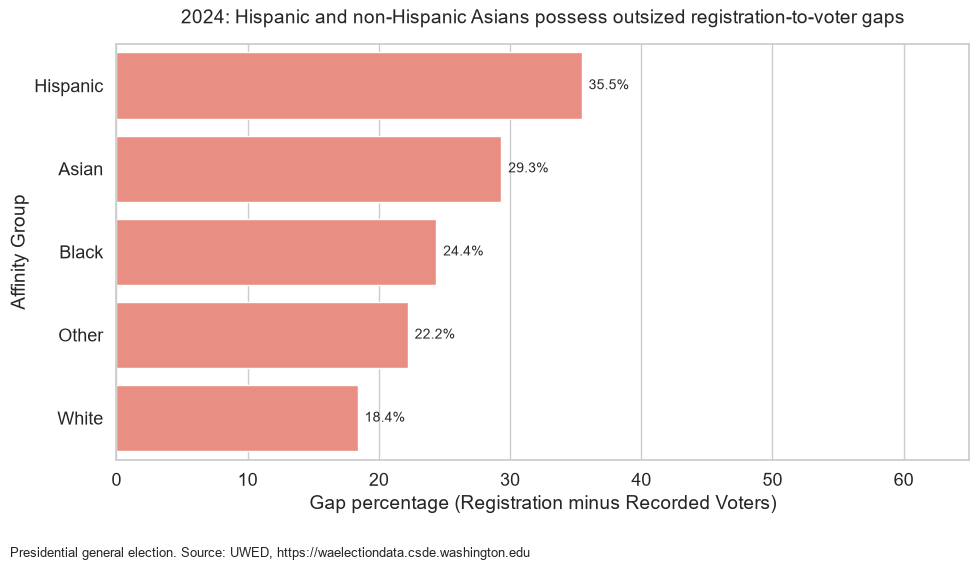

In [11]:
annual = observed_results.loc[observed_results['year'] == 2024].copy()
display(annual[['group', 'registrants', 'voters', 'gap_count', 'gap_pct']].round(2))

by_rate = annual.sort_values('gap_pct', ascending=False)
fig, ax = plt.subplots(figsize=(10, 5.8))
sns.barplot(data=by_rate, x='gap_pct', y='group', order=by_rate['group'],
            color='salmon', errorbar=None, ax=ax)
ax.set_xlim(0, 65)
ax.set_title('2024: Hispanic and non-Hispanic Asians possess outsized registration-to-voter gaps', pad=15)
ax.set_xlabel('Gap percentage (Registration minus Recorded Voters)')
ax.set_ylabel('Affinity Group')
for position in range(len(by_rate)):
    value = by_rate.iloc[position]['gap_pct']
    ax.annotate(f'{value:.1f}%', xy=(value, position), xytext=(5, 0),
                textcoords='offset points', va='center', fontsize=10)
fig.text(0.02, 0.02, 'Presidential general election. Source: UWED, https://waelectiondata.csde.washington.edu', fontsize=9)
fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

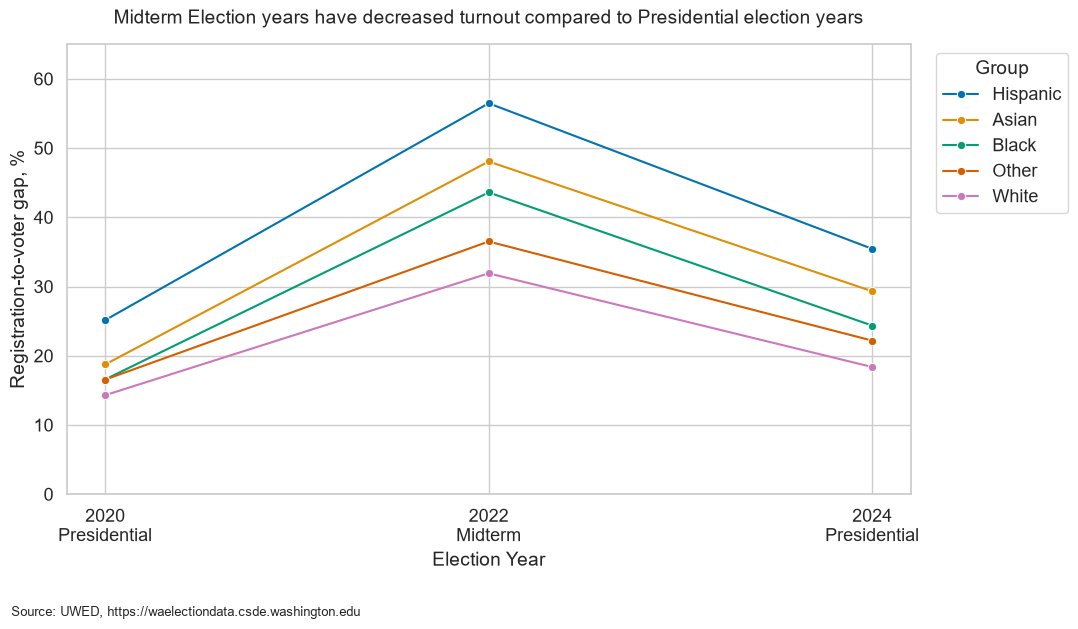

In [12]:
group_order = ['Hispanic', 'Asian', 'Black', 'Other', 'White']
percentage_long = percentage_gap_table.reset_index().melt(
    id_vars='Year', var_name='Group', value_name='Gap_percent'
)
percentage_long = percentage_long.dropna(subset=['Gap_percent'])

fig, ax = plt.subplots(figsize=(11, 6.4))
sns.lineplot(data=percentage_long, x='Year', y='Gap_percent', hue='Group',
             hue_order=group_order, palette='colorblind', marker='o', errorbar=None, ax=ax)
ax.set_ylim(0, 65)
ax.set_title('Midterm Election years have decreased turnout compared to Presidential election years', pad=15)
ax.set_xlabel('Election Year')
ax.set_ylabel('Registration-to-voter gap, %')
plt.xticks([2020, 2022, 2024], ['2020\nPresidential', '2022\nMidterm', '2024\nPresidential'])
ax.legend(title='Group', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.text(0.02, 0.02, 'Source: UWED, https://waelectiondata.csde.washington.edu', fontsize=9)
fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Section F -- Making Inferences Towards 2026

Because our dataset only spans three elections, I cannot build the mechanisms for making early forecasting because of a lack of robust data. It would be irresponsible to claim to be able to build a model that made reasonable predictions of 2026 voter behavior, especially because there is only a single dataset for a Midterm Election available for Washington state. For this reason, I chose not to attempt to build any kind of machine learning program to predict 2026 results. However, we can make some broad, high-level inferences about trends we may see.

First, I've plotted the changes registration-to-voter gaps between 2020 and 2024 (omitting 2022 for now). Surprisingly, non-Hispanic Asians have a slightly higher gap change percentage (0.28%) than Hispanics, with all other affinity groups showing smaller increases. 

,group,"2020 gap, pct","2024 gap, pct",change_pp
1,Asian,18.75,29.33,10.58
0,Hispanic,25.15,35.46,10.30
2,Black,16.59,24.37,7.78
3,Other,16.56,22.20,5.63
4,White,14.31,18.38,4.07


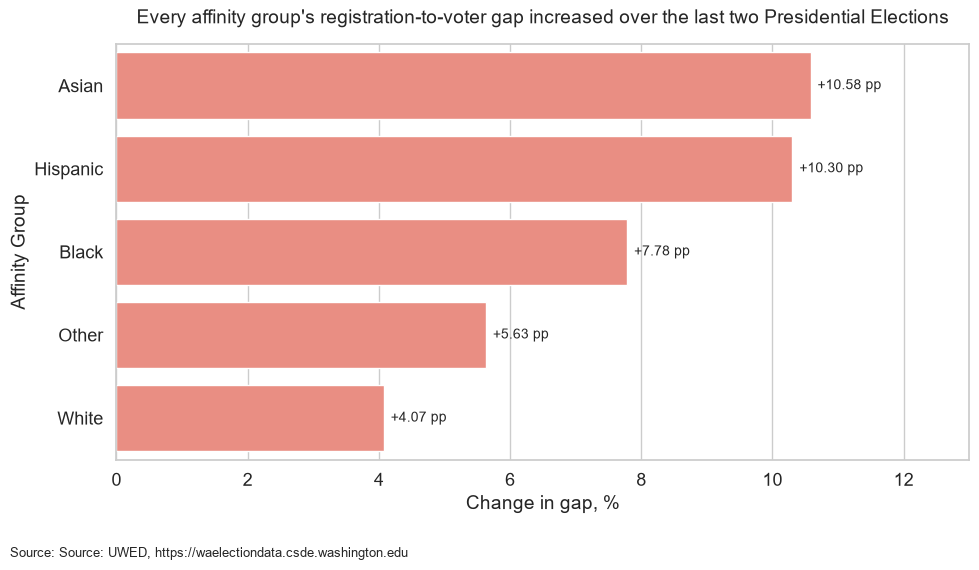

In [13]:
change_rows = []
for group in group_order:
    earlier = percentage_gap_table.loc[2020, group]
    later = percentage_gap_table.loc[2024, group]
    change_rows.append({'group': group, '2020 gap, pct': earlier,
                        '2024 gap, pct': later, 'change_pp': later - earlier})
changes = pd.DataFrame(change_rows).sort_values('change_pp', ascending=False)
display(changes.round(2))

fig, ax = plt.subplots(figsize=(10, 5.8))
sns.barplot(data=changes, x='change_pp', y='group', order=changes['group'],
            color='salmon', errorbar=None, ax=ax)
ax.set_xlim(0, 13)
ax.set_title('Every affinity group\'s registration-to-voter gap increased over the last two Presidential Elections', pad=15)
ax.set_xlabel('Change in gap, %')
ax.set_ylabel('Affinity Group')
for position in range(len(changes)):
    value = changes.iloc[position]['change_pp']
    ax.annotate(f'+{value:.2f} pp', xy=(value, position), xytext=(5, 0),
                textcoords='offset points', va='center', fontsize=10)
fig.text(0.02, 0.02, 'Source: Source: UWED, https://waelectiondata.csde.washington.edu', fontsize=9)
fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

Here, we can also see the overall changes between voter registration growth and accepted ballow growth between 2020 and 2024. Ballot growth is significant in Hispanic and non-Hispanic Asian populations, and those two populations are also the only two with accepted ballot growth - all three other affinity groups report fewer accepted ballots in 2024 than in 2020. This is a critical observation - we can conclude that voter registration is growing among Hispanic and non-Hispanic Asian populations, with accepted ballot returns struggling to keep pace, as opposed to other populations with meager registration growth and more noticable ballot return decreases.

In [14]:
growth_rows = []
for column, group in group_names.items():
    registration_growth = 100 * (registration_totals.loc[2024, column] /
                                  registration_totals.loc[2020, column] - 1)
    voter_growth = 100 * (voter_totals.loc[2024, column] /
                          voter_totals.loc[2020, column] - 1)
    growth_rows.append({'group': group, 'Registration Change, pct': registration_growth,
                        'Accepted Ballot Change, pct': voter_growth})
growth = pd.DataFrame(growth_rows)
display(growth.round(2))

,group,"Registration Change, pct","Accepted Ballot Change, pct"
0,Hispanic,16.73,0.66
1,Asian,15.60,0.54
2,Black,0.90,-8.51
3,Other,2.03,-4.86
4,White,0.84,-3.95


### Section G -- Results

First and foremost, Hispanic populations are most present in our registration-to-voter gap analysis, followed by non-Hispanic Asians. There are many hypothesis to this trend - language barriers, workforce or other workforce-related logistical issues preventing ballot return, and lack of historic affinity group political heritage that is not passed down between generations. I'll expand on all three of these hypothesis below.

First, a separate dataset provided by the Washington State Department of Health allows us to see the languages spoken at home by public school students in Washington state. 12.14% of enrolled students speak Spanish at home, with at least 1.61% of enrolled students speaking an East or South Asian language at home. I say 'at least' because the dataset only reports the top five languages recorded per school district. While state law mandates that public outreach information is published in the most populous languages represented in-state, there may be a reluctance to open and engage with mail primarily postmarked in English if English is not spoken by the parents or guardians at home.

Second, while Washington state does have a statewide mail-in ballot program, there are still logistical issues that may prevent our subject populations from effectively returning a ballot. Further data would be needed to fully trace the logistics of a ballot's travels from a ballot center to a voter's hands, and then back to a ballot return box, but significant barriers including mis-mailed ballots, misunderstandings about the ballots contents and voting process, and/or concerns that a ballot could be used to identify immigration status (a common fear among immigrant communities) are all potential sources of this gap.

Lastly, the lack of a durable 'political heritage' can explain some attitudes around voting. For example, Black Americans have an immensly rich political heritage dating back to the Reconstruction era, through Jim Crow and the Civil Rights era, up to the present day - children are often taught early about the importance of their vote and its value, accompanying parents to polling stations during elections in their childhood. Many immigrant communities in the United States do not have a similar political heritage, as first generation immigrants did not have elder family present in the country to teach them how voting worked when they were younger, and often this knowledge is not cultivated and passed on to second and third-generation immigrants.

Ultimately, my conclusion is that there is insufficient data and insufficient investigation to determine why these registration-to-voter gaps exist. However, I confidently stand by my findings in that Hispanic populations are most present in this gap, and it would be prudent for our civil society leaders to lead a deeper, quantitative and qualitative investigation into the sources of this gap. Democracy only works if everyone is present and able to participate in our elections, and ensuring parity in participation should be a priority for our leaders.

### Appendix -- Data Outputs and Citations

In [15]:
import os

os.makedirs('results', exist_ok=True)

checks_table = pd.DataFrame(data_checks)

results.to_csv('results/statewide_gaps.csv', index=False)
coverage.to_csv('results/election_coverage.csv', index=False)
winners.to_csv('results/annual_winners.csv', index=False)
changes.to_csv('results/change_2020_2024.csv', index=False)
growth.to_csv('results/population_growth_2020_2024.csv', index=False)
checks_table.to_csv('results/data_checks.csv', index=False)

### Works Cited

“Black Americans and the Vote.” *National Archives*, U.S. National Archives and Records Administration, 9 June 2021, [www.archives.gov/research/african-americans/vote](https://www.archives.gov/research/african-americans/vote). Accessed 25 Oct. 2026.

“Data Sets.” *University of Washington Elections Database*, University of Washington, [waelectiondata.csde.washington.edu/p_010_data.html](https://waelectiondata.csde.washington.edu/p_010_data.html). Accessed 25 Oct. 2026.

“pandas.DataFrame.update.” *pandas Documentation*, [pandas.pydata.org/docs/reference/api/pandas.DataFrame.update.html](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.update.html). Accessed 25 Oct. 2026.

“Technical Documentation.” *University of Washington Elections Database*, University of Washington, [waelectiondata.csde.washington.edu/p_050_techdoc.html](https://waelectiondata.csde.washington.edu/p_050_techdoc.html). Accessed 25 Oct. 2026.

Washington Tracking Network. “Languages Spoken at Home.” *Washington State Geospatial Open Data Portal*, Washington State Department of Health, Sept. 2025, [geo.wa.gov/datasets/1855f4fa44ca45968646d7e0a5a80afb_0/explore](https://geo.wa.gov/datasets/1855f4fa44ca45968646d7e0a5a80afb_0/explore). Accessed 25 Oct. 2026. [Table view of the same dataset](https://geo.wa.gov/datasets/1855f4fa44ca45968646d7e0a5a80afb_0/explore?location=47.270405%2C-120.803995%2C6&showTable=true).
